# Mg–Ca: full phase diagram

The complete Mg–Ca phase diagram from 200 K to 1300 K, computed with landau from calphy/ACE free energies
of all solid phases and the liquid.

Writes `MgCa_Phasediagram_Full.svg` and `.png` (transparent) next to the notebook.

## Setup

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import landau as ld

warnings.simplefilter("ignore", DeprecationWarning)

/home/pmrv/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/claude-1000/matplotlib-tf_e3oje because there was an issue with the default path (/home/pmrv/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [2]:
DATA = "../Intro/MgCaFreeEnergies.pckl.gz"
OUT = "MgCa_Phasediagram_Full.svg"

T_RANGE = (200, 1300)
LIQ = "liquid"
PHASE_COLOR = {"hcp Mg": "#a1c9f4", "Mg$_2$Ca": "#ffb482", "bcc Ca": "#ff9f9b", "fcc Ca": "#8de5a1", LIQ: "#debb9b"}
MIN_C_WIDTH = 0.005

FIGSIZE = (7, 5.5)  # inches
FONTSIZE = 15
DPI = 150

## Phases

Solids are line compounds; the liquid interpolates between its line-phase free energies.

In [3]:
raw = pd.read_pickle(DATA)


def line(r):
    return ld.phases.TemperatureDependentLinePhase(
        r.phase, r.composition, r.temperature, r.free_energy, interpolator=ld.interpolate.SGTE(4)
    )


solids = [line(r) for _, r in raw[raw.phase != LIQ].iterrows()]
liquid = ld.phases.FastInterpolatingPhase(LIQ, [line(r) for _, r in raw[raw.phase == LIQ].iterrows()])
phases = solids + [liquid]

## Calculate

In [4]:
df = ld.calculate.calc_phase_diagram(phases, Ts=np.linspace(*T_RANGE, 60), mu=200)
df.query("stable").groupby("phase").T.agg(["min", "max"])

,min,max
phase,,
Mg$_2$Ca,200.000000,928.705645
bcc Ca,435.560645,1081.538592
fcc Ca,200.000000,435.560646
hcp Mg,200.000000,857.774269
liquid,613.442672,1300.000000


## Plot

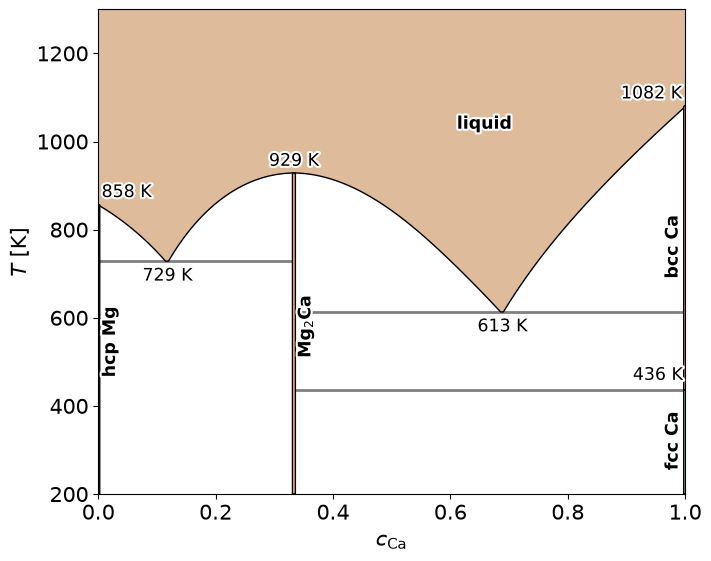

In [5]:
plt.rcParams.update({"font.size": FONTSIZE, "svg.fonttype": "none"})
fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
ld.plot.plot_phase_diagram(
    df, element="Ca", color_override=PHASE_COLOR, triplepoints=True, transition_temperatures=True, ax=ax,
    poly_method=ld.poly.SegmentFastTsp(min_c_width=MIN_C_WIDTH),
)
seen = set()  # the bcc/fcc Ca transition is labelled from both sides; keep one
for t in list(ax.texts):
    key = (t.get_text(), round(t.get_position()[0], 2))
    if key in seen:
        t.remove()
    seen.add(key)
ax.set_xlim(0, 1)
ax.set_ylim(*T_RANGE)

fig.savefig(OUT)
fig.savefig(OUT.replace(".svg", ".png"), dpi=DPI, transparent=True)